# Corporate Default Prediction

XGBoost classifier predicting US public company bankruptcy from NYSE/NASDAQ accounting
data (1999-2018).

**Dataset:** [American Companies Bankruptcy Prediction](https://www.kaggle.com/datasets/utkarshx27/american-companies-bankruptcy-prediction-dataset) - 78,682 firm-year observations from 8,971 companies.

**Task:** from fiscal year `t` accounting data, does the firm make its final filing within
the next two years?

**Approach:** discrete-time hazard label, temporal split with a two-year embargo,
preprocessing fit on train only, benchmarked against Altman Z (1968) and penalised
logistic regression, evaluated on capture rate at a review budget with cluster-bootstrap
confidence intervals.

In [1]:
import sys, os, platform

print("interpreter:", sys.executable)
print("cwd:        ", os.getcwd())
print("python:     ", platform.python_version())

# Expect interpreter to end in: corp-default\.venv\Scripts\python.exe
# If it does not, select the "corp-default (uv)" kernel before running anything else.


interpreter: C:\Users\lenam\projects\corp-default\.venv\Scripts\python.exe
cwd:         C:\Users\lenam\projects\corp-default
python:      3.13.8


In [2]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import (
    roc_auc_score, precision_recall_curve, auc,
    confusion_matrix, classification_report, roc_curve
)
from sklearn.model_selection import ParameterSampler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import shap
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

HORIZON = 2          # label window in years
PANEL_END = 2018     # last year present in the dataset
TRAIN_END = 2006
VAL_START, VAL_END = 2009, 2011
TEST_START, TEST_END = 2014, 2016

# Minimum boosting rounds a configuration must reach to be eligible for selection.
# A gradient-boosted model that early-stops at one or two rounds is not a boosted model,
# and PR-AUC on a few hundred validation positives is noisy enough to produce such a
# round by chance. The floor is a constraint on model form, set without reference to any
# candidate configuration test score.
MIN_BOOST_ROUNDS = 10

assert VAL_START >= TRAIN_END + HORIZON + 1, "embargo before validation is too narrow"
assert TEST_START >= VAL_END + HORIZON + 1, "embargo before test is too narrow"

## Data Loading

In [3]:
COLUMN_MAP = {
    "X1": "current_assets",
    "X2": "cogs",
    "X3": "depreciation_amort",
    "X4": "ebitda",
    "X5": "inventory",
    "X6": "net_income",
    "X7": "total_receivables",
    "X8": "market_cap",
    "X9": "net_sales",
    "X10": "total_assets",
    "X11": "total_lt_debt",
    "X12": "ebit",
    "X13": "gross_profit",
    "X14": "total_current_liabilities",
    "X15": "retained_earnings",
    "X16": "total_revenue",
    "X17": "total_liabilities",
    "X18": "total_operating_expenses",
}


def load_raw():
    """Read the panel and apply readable column names.

    Called once for the main pipeline and again by the horizon sensitivity check,
    which needs an unlabelled frame to relabel at a different horizon.
    """
    frame = pd.read_csv("data/american_bankruptcy.csv").rename(columns=COLUMN_MAP)
    # total_revenue is identical to net_sales. company_name and status_label are kept:
    # the label is derived from them, and company_name is needed for the cluster
    # bootstrap and the unseen-company check. Neither ever enters feature_cols.
    return frame.drop(columns=["total_revenue"])


df = load_raw()
print(f"Shape: {df.shape}")

lifetime_failed = df.groupby("company_name")["status_label"].apply(
    lambda s: (s == "failed").any())
print(f"Companies: {len(lifetime_failed):,}, of which {int(lifetime_failed.sum()):,} "
      f"are labelled failed at some point ({lifetime_failed.mean():.1%}). That is a "
      "company-level lifetime rate, not a firm-year default rate.")

df.head()

Shape: (78682, 20)


Companies: 8,971, of which 609 are labelled failed at some point (6.8%). That is a company-level lifetime rate, not a firm-year default rate.


,company_name,status_label,year,current_assets,cogs,depreciation_amort,ebitda,inventory,net_income,total_receivables,market_cap,net_sales,total_assets,total_lt_debt,ebit,gross_profit,total_current_liabilities,retained_earnings,total_liabilities,total_operating_expenses
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,407.608,604.467


## Label Construction

`status_label` is a company-level attribute, not a firm-year event: every row of a company
that eventually failed carries `failed`, including rows from fifteen years before the
failure. Used directly it encodes "this company failed at some point in 1999-2018", which
is why the raw firm-year default rate falls from 7.2% to 1.3% across the panel. That
decline is survivorship, not the credit cycle.

The label below is a discrete-time hazard target: from fiscal year `t` accounting data,
does the firm make its final filing in `t+1` or `t+2`?

Two sets of rows are removed. The terminal year of a failed company, because its
financials are contemporaneous with the event and predicting from them is a nowcast
rather than a forecast. And any row whose outcome window runs past the end of the panel,
because the label cannot be observed.

Companies labelled `alive` that stop reporting before 2018 are treated as right-censored
and labelled 0 throughout. Only 32% of them survive to 2018; the rest are delisted,
acquired, or simply stop filing. Since those exits are not independent of credit quality,
this biases the model mildly toward optimism. It is a limitation of the dataset.

**One positive in five, in the test window only, is unconfirmed.** `status_label` carries
no date. A firm is positive at year `t` when it is marked `failed` and its last row in the
panel falls in `t+1` or `t+2`, and "last row in the panel" is inferred from the absence of
a later one. For an interior year that inference is sound, because a subsequent non-filing
year is visible in the data. For a firm whose last row is 2018 it is not, because the panel
simply stops there. The split cell below prints the count: 35 of the 160 test positives,
21.9%, rest on a 2018 final filing, against none in train and none in validation. The
asymmetry sits entirely in test, and its direction is conservative - any of those 35 that
in fact kept filing after 2018 is a mislabelled positive, which depresses measured
performance rather than flattering it.

In [4]:
def build_label(frame, horizon):
    """Discrete-time hazard label at a given horizon.

    Returns the frame with `target` set, minus the terminal-year rows of failed
    companies and any row whose outcome window runs past PANEL_END. Written as a
    function because the horizon sensitivity check relabels at 1 and 3 years.
    """
    frame = frame.join(frame.groupby("company_name")["year"].max().rename("last_year"),
                       on="company_name")
    frame["failed"] = frame["status_label"] == "failed"
    frame["years_to_final"] = frame["last_year"] - frame["year"]
    frame = frame[~(frame["failed"] & (frame["years_to_final"] == 0))]
    frame = frame[frame["year"] + horizon <= PANEL_END].copy()
    frame["target"] = (frame["failed"]
                       & frame["years_to_final"].between(1, horizon)).astype(int)
    return frame


n_raw = len(df)
df = build_label(df, HORIZON)

print(f"dropped {n_raw - len(df):,} rows: terminal years of failed companies, "
      f"plus rows whose {HORIZON}-year outcome window exceeds {PANEL_END}")
print(f"modelling frame: {len(df):,} rows, {df['target'].sum():,} positives "
      f"({df['target'].mean():.3%} base rate)")

dropped 6,289 rows: terminal years of failed companies, plus rows whose 2-year outcome window exceeds 2018
modelling frame: 72,393 rows, 1,123 positives (1.551% base rate)


In [5]:
# Leakage guards. These run on every execution of this notebook.

# Non-vacuity floor FIRST. The two checks below filter to target == 1 before
# calling .all(), and pandas returns True for .all() on an empty Series - so if
# target ever collapsed to all-zero they would both pass while the label was
# entirely broken. Pinning the count closes that hole.
assert df["target"].sum() == 1123, \
    f"expected 1,123 positives, got {df['target'].sum():,}"

assert not (df["failed"] & (df["years_to_final"] == 0)).any(), \
    "terminal-year rows of failed companies must be dropped"
assert df["year"].max() == PANEL_END - HORIZON, \
    f"latest observable year must be {PANEL_END - HORIZON}"
assert df.loc[df["target"] == 1, "failed"].all(), \
    "positive labels may only be carried by companies that failed"
assert df.loc[df["target"] == 1, "years_to_final"].between(1, HORIZON).all(), \
    "positives must fall strictly inside the horizon window"
print("label assertions passed")

label assertions passed


## Exploratory Data Analysis

In [6]:
print(f"Horizon: {HORIZON} years")
print(f"Base rate: {df['target'].mean():.3%}  ({df['target'].sum():,} of {len(df):,} firm-years)")
print(f"\nDistinct companies: {df['company_name'].nunique():,}")
print(f"Companies with at least one positive firm-year: "
      f"{df.loc[df['target'] == 1, 'company_name'].nunique():,}")
print(f"\nFirm-year label distribution:\n"
      f"{df['target'].value_counts().rename({0: 'no failure within horizon', 1: 'failure within horizon'})}")

Horizon: 2 years
Base rate: 1.551%  (1,123 of 72,393 firm-years)

Distinct companies: 8,828
Companies with at least one positive firm-year: 594

Firm-year label distribution:
target
no failure within horizon    71270
failure within horizon        1123
Name: count, dtype: int64


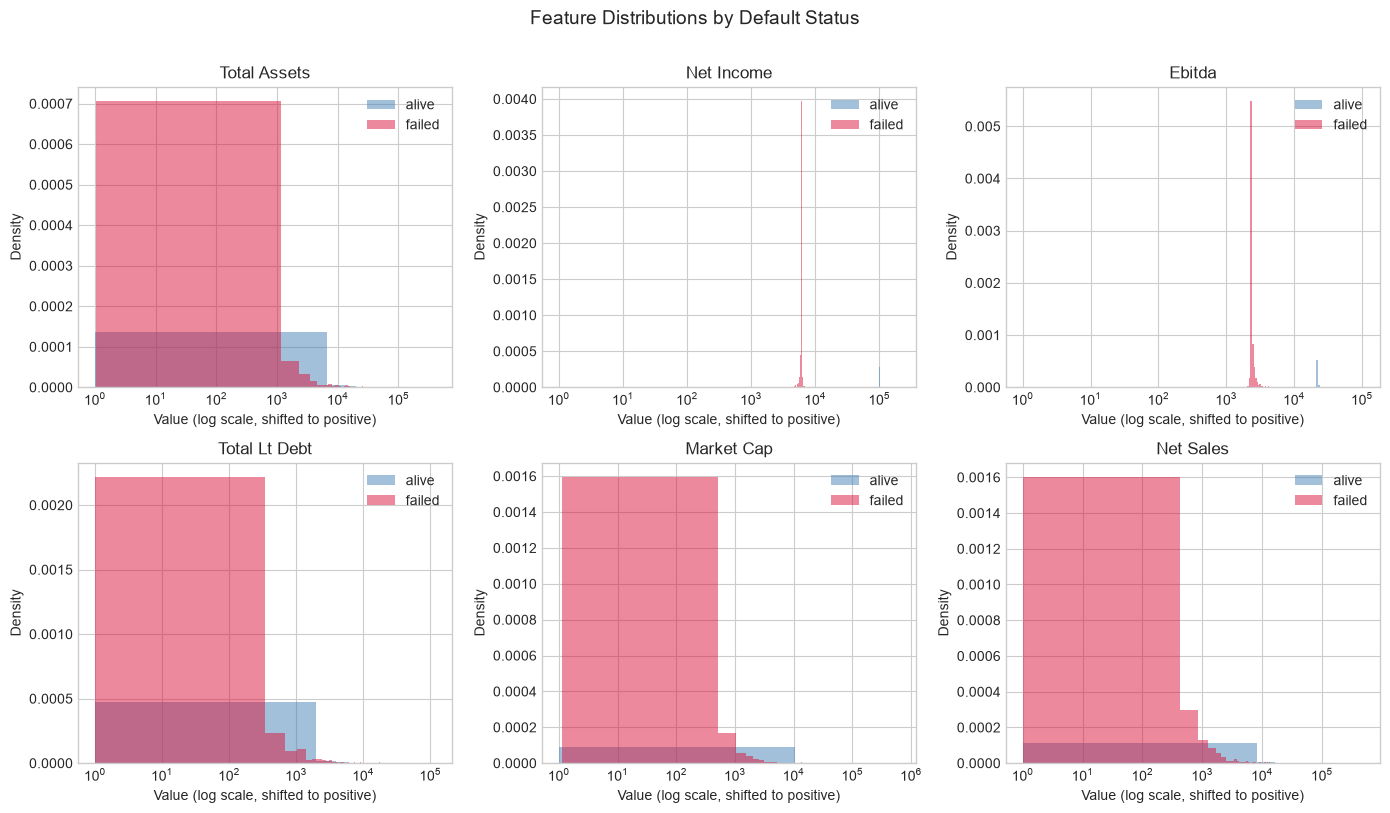

In [7]:
# Feature distributions split by default status - 6 key financial variables
key_features = ["total_assets", "net_income", "ebitda", "total_lt_debt", "market_cap", "net_sales"]
labels = {0: "alive", 1: "failed"}
colors = {0: "steelblue", 1: "crimson"}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(key_features):
    ax = axes[i]
    for target_val in [0, 1]:
        subset = df.loc[df["target"] == target_val, col].dropna()
        # Shift to positive domain for log scale (add small offset if needed)
        shift = max(0, -subset.min()) + 1
        ax.hist(
            subset + shift,
            bins=60,
            alpha=0.5,
            color=colors[target_val],
            label=labels[target_val],
            density=True,
        )
    ax.set_xscale("log")
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("Value (log scale, shifted to positive)")
    ax.set_ylabel("Density")
    ax.legend()

fig.suptitle("Feature Distributions by Default Status", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## Feature Engineering

In [8]:
def add_features(frame):
    """Engineered credit ratios. Called once here and again by the horizon check."""
    ta = frame["total_assets"].replace(0, np.nan)
    sales = frame["net_sales"].replace(0, np.nan)
    tl = frame["total_liabilities"].replace(0, np.nan)

    frame["current_ratio"] = frame["current_assets"] / ta
    frame["debt_to_assets"] = frame["total_lt_debt"] / ta
    frame["net_margin"] = frame["net_income"] / sales
    frame["ebitda_margin"] = frame["ebitda"] / sales
    frame["roa"] = frame["net_income"] / ta
    frame["gross_margin"] = frame["gross_profit"] / sales
    frame["asset_turnover"] = frame["net_sales"] / ta

    # debt_to_ebitda is meaningless when EBITDA is negative: the ratio flips sign and a
    # distressed firm sorts as conservatively levered. Blank it and carry the
    # information in an explicit flag instead.
    frame["negative_ebitda"] = (frame["ebitda"] <= 0).astype(int)
    frame["debt_to_ebitda"] = np.where(frame["ebitda"] > 0,
                                       frame["total_lt_debt"] / frame["ebitda"], np.nan)

    # Altman Z components. asset_turnover above is already the fifth term (Sales / TA).
    frame["working_capital_to_assets"] = (
        frame["current_assets"] - frame["total_current_liabilities"]) / ta
    frame["retained_earnings_to_assets"] = frame["retained_earnings"] / ta
    frame["ebit_to_assets"] = frame["ebit"] / ta
    frame["mve_to_liabilities"] = frame["market_cap"] / tl

    # Gearing on total liabilities, not long-term debt alone.
    frame["total_liabilities_to_assets"] = frame["total_liabilities"] / ta
    return frame


NON_FEATURES = ["company_name", "status_label", "year", "target",
                "failed", "years_to_final", "last_year"]

df = add_features(df)
feature_cols = [c for c in df.columns if c not in NON_FEATURES]
print(f"{len(feature_cols)} features")

31 features


In [9]:
# Non-vacuity floor first: the isna() check below filters before .all(), and an
# empty selection returns True.
assert (df["ebitda"] <= 0).any(), "expected some non-positive EBITDA rows to exist"
assert len(feature_cols) == 31, f"expected 31 features, got {len(feature_cols)}"

assert df.loc[df["ebitda"] <= 0, "debt_to_ebitda"].isna().all(), \
    "debt_to_ebitda must be blank wherever EBITDA is non-positive"
assert df.loc[df["ebitda"] > 0, "debt_to_ebitda"].notna().all(), \
    "debt_to_ebitda must be populated wherever EBITDA is positive"
assert not any(c in feature_cols for c in NON_FEATURES), \
    "identifier or label columns leaked into feature_cols"
assert "company_name" in df.columns, "company_name is needed downstream"
print(f"feature assertions passed - {len(feature_cols)} features, no identifiers")

feature assertions passed - 31 features, no identifiers


| Ratio | Formula | Measures |
|-------|---------|----------|
| `current_ratio` | Current Assets / Total Assets | Liquidity |
| `debt_to_assets` | Long-Term Debt / Total Assets | Leverage |
| `total_liabilities_to_assets` | Total Liabilities / Total Assets | Gearing |
| `net_margin` | Net Income / Net Sales | Profitability |
| `ebitda_margin` | EBITDA / Net Sales | Operating efficiency |
| `roa` | Net Income / Total Assets | Return on assets |
| `gross_margin` | Gross Profit / Net Sales | Pricing power |
| `asset_turnover` | Net Sales / Total Assets | Asset utilization |
| `debt_to_ebitda` | Long-Term Debt / EBITDA, blank if EBITDA <= 0 | Debt serviceability |
| `negative_ebitda` | 1 if EBITDA <= 0 | Distress flag |
| `working_capital_to_assets` | (Current Assets - Current Liabilities) / Total Assets | Altman: liquidity |
| `retained_earnings_to_assets` | Retained Earnings / Total Assets | Altman: cumulative profitability |
| `ebit_to_assets` | EBIT / Total Assets | Altman: operating return |
| `mve_to_liabilities` | Market Cap / Total Liabilities | Altman: market cushion |

The last four are the Altman Z components; `asset_turnover` is its fifth term. Keeping
`market_cap` and `mve_to_liabilities` makes this a hybrid market/fundamental model rather
than a pure accounting one, since equity value collapsing ahead of bankruptcy is a market
signal.

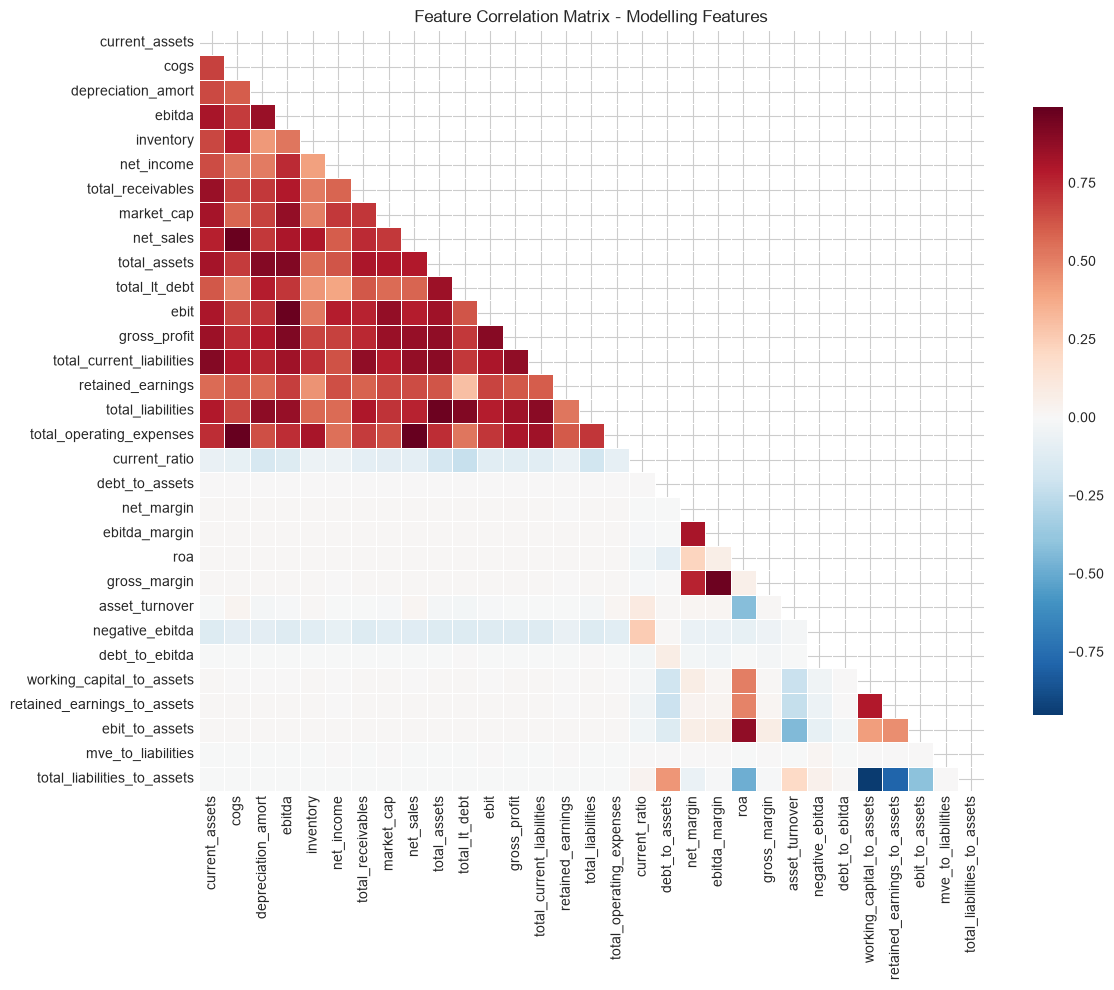

In [10]:
fig, ax = plt.subplots(figsize=(12, 10))
corr = df[feature_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, ax=ax,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
ax.set_title("Feature Correlation Matrix - Modelling Features")
plt.tight_layout()
plt.show()

## Train / Validation / Test Split

A row from year `t` is labelled on whether the firm's final filing falls in `t+1` or
`t+2`. Resolving that label reads filing records through `t+2`, and strictly one year
further than that: what establishes a `t+2` filing as *final* is the absence of a `t+3`
one. The embargo is `HORIZON` years wide rather than `HORIZON + 1` because the extra year
enters only as an absence, and an absence carries nothing across the boundary - a company
whose last filing is `t+2` has no row in the next split for it to leak into. Embargo years
are dropped entirely rather than assigned to either side.

- **Train:** 1999-2006
- *embargo:* 2007-2008
- **Validation:** 2009-2011
- *embargo:* 2012-2013
- **Test:** 2014-2016

The train window ends before the financial crisis, which costs the 2009-2010 failure
cohort. Firms making their final filing in 2007-2008 remain in training, labelled on
2005-2006 rows, and the 2001-2002 dot-com bust sits entirely inside the training window.
This allocation was chosen because it maximises the test set at 160 positives; the
alternatives trade test positives for training data and are tabulated in the design spec.

Note what this does and does not defend against. A temporal split with an embargo prevents
look-ahead leakage. It does not make the company sets disjoint - 2,264 of the 3,854 test
companies, 58.7%, also appear in training, as the cell below prints. Under the old
company-constant label that was fatal, because firm identity gave away the answer. Under a
time-varying hazard label it is far less harmful, and the unseen-company check further
down quantifies what remains.

In [11]:
train = df[df["year"] <= TRAIN_END]
val = df[df["year"].between(VAL_START, VAL_END)]
test = df[df["year"].between(TEST_START, TEST_END)]

for name, part in [("Train", train), ("Val", val), ("Test", test)]:
    print(f"{name:6s} {part['year'].min()}-{part['year'].max()}  "
          f"{len(part):7,} rows  {part['target'].sum():4,} positives  "
          f"{part['target'].mean():.2%} base rate")

embargoed = len(df) - len(train) - len(val) - len(test)
print(f"\n{embargoed:,} rows dropped to embargo years "
      f"{TRAIN_END + 1}-{TRAIN_END + HORIZON} and {VAL_END + 1}-{VAL_END + HORIZON}")

# The embargo makes the split temporal. It does not make the company sets disjoint, and
# that overlap is quoted often enough downstream that it should be computed, not typed.
test_companies = set(test["company_name"])
overlap = test_companies & set(train["company_name"])
print(f"\nCompany overlap: {len(overlap):,} of {len(test_companies):,} test companies "
      f"({len(overlap) / len(test_companies):.1%}) also appear in training; "
      f"{len(test_companies) - len(overlap):,} do not")

# A positive resting on a final filing in PANEL_END cannot be confirmed: the panel ends
# there, so a firm that kept filing afterwards is indistinguishable from one that stopped.
print()
for name, part in [("train", train), ("val", val), ("test", test)]:
    pos = part[part["target"] == 1]
    unconfirmed = int((pos["last_year"] == PANEL_END).sum())
    print(f"{name:5s}: {unconfirmed:3d} of {len(pos):3d} positives "
          f"({unconfirmed / len(pos):5.1%}) rest on a final filing in {PANEL_END}, "
          "which the panel cannot confirm is final")

Train  1999-2006   36,977 rows   547 positives  1.48% base rate
Val    2009-2011   10,798 rows   157 positives  1.45% base rate
Test   2014-2016    9,954 rows   160 positives  1.61% base rate

14,664 rows dropped to embargo years 2007-2008 and 2012-2013

Company overlap: 2,264 of 3,854 test companies (58.7%) also appear in training; 1,590 do not

train:   0 of 547 positives ( 0.0%) rest on a final filing in 2018, which the panel cannot confirm is final
val  :   0 of 157 positives ( 0.0%) rest on a final filing in 2018, which the panel cannot confirm is final
test :  35 of 160 positives (21.9%) rest on a final filing in 2018, which the panel cannot confirm is final


In [12]:
# The embargo invariant, executed rather than asserted in prose.
assert train["year"].max() + HORIZON < VAL_START, \
    "train labels reach into the validation window"
assert val["year"].max() + HORIZON < TEST_START, \
    "validation labels reach into the test window"

# Pinned sizes: a split silently emptying would otherwise sail through the
# base-rate spread check below on NaN comparisons.
for name, part, n_rows, n_pos in [("train", train, 36977, 547),
                                  ("val", val, 10798, 157),
                                  ("test", test, 9954, 160)]:
    assert len(part) == n_rows, f"{name}: expected {n_rows:,} rows, got {len(part):,}"
    assert part["target"].sum() == n_pos, \
        f"{name}: expected {n_pos} positives, got {part['target'].sum()}"

rates = [train["target"].mean(), val["target"].mean(), test["target"].mean()]
assert max(rates) - min(rates) < 0.003, f"base rates drifted across splits: {rates}"
assert len(set(train["year"]) & set(val["year"])) == 0
assert len(set(val["year"]) & set(test["year"])) == 0
print(f"split assertions passed - base rates {[f'{r:.2%}' for r in rates]}, "
      f"spread {max(rates) - min(rates):.4f}")

split assertions passed - base rates ['1.48%', '1.45%', '1.61%'], spread 0.0015


### Preprocessing

Winsorisation bounds and imputation medians are computed on the training split alone and
applied unchanged to validation and test. Fitting them on the full panel - as the previous
version did - lets the test period influence the clipping thresholds and the fill values
every split receives, which is leakage even though no label is involved.

Medians are taken after clipping so that a handful of extreme rows cannot drag the fill
value, and clipping is applied before imputation so that filled values are never themselves
clipped.

The cost of doing it this way is compression of the later period, and it belongs in the
open rather than left for a reviewer to find. Train-fitted bounds pin exactly 1% of
training rows at the upper bound by construction, but 3.4% of test rows for `total_assets`.
The panel's firms are larger in 2014-2016 than in 1999-2006, so everything above the
training 99th percentile is flattened onto one value. Other level variables behave the same
way, printed below. Refitting the bounds on test would be leakage, so the compression is
accepted; what it discards is dispersion among the largest test firms, which is not where
the defaults are.

In [13]:
def fit_prepare(train_frame, cols):
    """Fit winsorisation bounds and fill medians on the TRAINING split only.

    Returns a `prepare` closure plus the fitted statistics so they can be asserted on.
    Written as a function so the horizon check refits cleanly on its own train split
    rather than reusing statistics fitted here.
    """
    lower = train_frame[cols].quantile(0.01)
    upper = train_frame[cols].quantile(0.99)
    medians = train_frame[cols].clip(lower, upper, axis=1).median()

    def prepare(frame):
        return frame[cols].clip(lower, upper, axis=1).fillna(medians)

    return prepare, lower, upper, medians


prepare, lower, upper, medians = fit_prepare(train, feature_cols)

X_train, y_train = prepare(train), train["target"]
X_val, y_val = prepare(val), val["target"]
X_test, y_test = prepare(test), test["target"]

print(f"X_train {X_train.shape}  X_val {X_val.shape}  X_test {X_test.shape}")
print(f"NaN remaining: {int(X_train.isna().sum().sum() + X_val.isna().sum().sum() + X_test.isna().sum().sum())}")

# Train-fitted bounds compress the later period. Quantify it rather than assert it.
print("\nRows pinned at the train-fitted upper bound (train is 1% by construction):")
for col in ["total_assets", "total_lt_debt", "retained_earnings", "total_liabilities"]:
    print(f"  {col:22s} train {(X_train[col] == upper[col]).mean():5.1%}   "
          f"test {(X_test[col] == upper[col]).mean():5.1%}")

X_train (36977, 31)  X_val (10798, 31)  X_test (9954, 31)
NaN remaining: 0

Rows pinned at the train-fitted upper bound (train is 1% by construction):
  total_assets           train  1.0%   test  3.4%
  total_lt_debt          train  1.0%   test  3.9%
  retained_earnings      train  1.0%   test  3.5%
  total_liabilities      train  1.0%   test  3.4%


In [14]:
# Preprocessing statistics must derive from train only.
assert lower.equals(train[feature_cols].quantile(0.01)), "clip bounds are not train-fitted"
assert upper.equals(train[feature_cols].quantile(0.99)), "clip bounds are not train-fitted"

# The sharp version of the same claim: bounds fitted on train must NOT coincide with
# bounds fitted on the whole panel. If they did, the split would be doing nothing and
# the check above would pass anyway.
assert not upper.equals(df[feature_cols].quantile(0.99)), \
    "clip bounds match full-panel bounds - preprocessing is not actually train-only"

for name, mat, n_rows in [("train", X_train, 36977), ("val", X_val, 10798),
                          ("test", X_test, 9954)]:
    assert mat.shape == (n_rows, 31), f"{name}: expected ({n_rows}, 31), got {mat.shape}"
    assert not mat.isna().any().any(), f"{name} still contains NaN"
    assert (mat.max() <= upper + 1e-9).all(), f"{name} exceeds train-fitted upper bound"
    assert (mat.min() >= lower - 1e-9).all(), f"{name} falls below train-fitted lower bound"

assert list(X_train.columns) == feature_cols
print("preprocessing assertions passed - all statistics fit on train only")

preprocessing assertions passed - all statistics fit on train only


## Baselines

Two comparators, both scored through exactly the same evaluation path as the model.

**Altman Z-score (1968).** The published public-firm coefficients, applied without
refitting. Its weights were estimated on 66 manufacturers in 1968 and have never seen this
data, which makes it a genuine zero-parameter benchmark rather than a courtesy. Z is a
solvency score where higher is safer, so it is negated to become a risk score. One
qualification on "never seen this data": the coefficients are untouched, but the five
ratios they are applied to are read off `X_test`, so they have been winsorised at
train-fitted bounds and median-imputed where missing. The formula is unfitted; its inputs
were transformed using statistics fitted on this panel's training split.

**Penalised logistic regression.** L2, standardised inputs, balanced class weights. This
separates two questions that a single XGBoost number conflates: how much of the signal is
in the ratios themselves, and how much comes from gradient boosting finding non-linear
structure in them.

An AUC without a baseline is uninterpretable. If XGBoost with 36,977 training rows and 40
tuning iterations cannot clear a fifty-year-old five-ratio formula by a wide margin, that
is the most useful thing this notebook can report.

In [15]:
def altman_z(frame):
    """Altman (1968) public-firm Z-score. Higher is safer."""
    return (1.2 * frame["working_capital_to_assets"]
            + 1.4 * frame["retained_earnings_to_assets"]
            + 3.3 * frame["ebit_to_assets"]
            + 0.6 * frame["mve_to_liabilities"]
            + 1.0 * frame["asset_turnover"])


logit = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0, random_state=42),
)
logit.fit(X_train, y_train)

baseline_scores = {
    "Altman Z (1968)": -altman_z(X_test).to_numpy(),   # negate: higher = riskier
    "Logistic regression": logit.predict_proba(X_test)[:, 1],
}

for name, scores in baseline_scores.items():
    prec, rec, _ = precision_recall_curve(y_test, scores)
    print(f"{name:22s} ROC-AUC {roc_auc_score(y_test, scores):.4f}   "
          f"PR-AUC {auc(rec, prec):.4f}")

Altman Z (1968)        ROC-AUC 0.7166   PR-AUC 0.0282
Logistic regression    ROC-AUC 0.7316   PR-AUC 0.0441


## XGBoost Model

### Hyperparameter Tuning

Randomized search over a structured parameter grid, scored on PR-AUC (more informative than ROC-AUC under heavy class imbalance). The validation set (2009-2011) is used for early stopping and tuning - the test set (2014-2016) remains untouched until final evaluation.

In [16]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos = neg_count / pos_count

param_grid = {
    "max_depth": [3, 4, 5, 6, 7, 8],
    "min_child_weight": [1, 3, 5, 10, 20],
    "subsample": [0.6, 0.7, 0.8, 0.9],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 0.9],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1.0],
    "reg_lambda": [1.0, 2.0, 5.0, 10.0],
    "learning_rate": [0.005, 0.01, 0.02],
}

INT_PARAMS = {"max_depth", "min_child_weight"}

n_iter = 40
sampled_params = list(ParameterSampler(param_grid, n_iter=n_iter, random_state=42))

results = []
for i, params in enumerate(sampled_params):
    # Cast integer params
    params = {k: int(v) if k in INT_PARAMS else v for k, v in params.items()}

    model_i = xgb.XGBClassifier(
        n_estimators=2000,
        scale_pos_weight=scale_pos,
        eval_metric="aucpr",
        early_stopping_rounds=50,
        random_state=42,
        n_jobs=-1,
        **params,
    )
    model_i.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=0)

    y_prob_val = model_i.predict_proba(X_val)[:, 1]
    val_roc = roc_auc_score(y_val, y_prob_val)
    prec_i, rec_i, _ = precision_recall_curve(y_val, y_prob_val)
    val_pr = auc(rec_i, prec_i)

    results.append({
        "iter": i,
        "val_pr_auc": val_pr,
        "val_roc_auc": val_roc,
        "best_iteration": model_i.best_iteration,
        **params,
    })
    if (i + 1) % 10 == 0:
        print(f"  {i+1}/{n_iter} done - best PR-AUC so far: {max(r['val_pr_auc'] for r in results):.4f}")

tuning_df = pd.DataFrame(results).sort_values("val_pr_auc", ascending=False)
print(f"\nTop 5 configurations by validation PR-AUC:")
print(tuning_df.head()[["val_pr_auc", "val_roc_auc", "best_iteration",
                         "learning_rate", "max_depth", "min_child_weight",
                         "subsample", "colsample_bytree", "gamma",
                         "reg_alpha", "reg_lambda"]].to_string(index=False))

  10/40 done - best PR-AUC so far: 0.0734


  20/40 done - best PR-AUC so far: 0.0758


  30/40 done - best PR-AUC so far: 0.0907


  40/40 done - best PR-AUC so far: 0.0907

Top 5 configurations by validation PR-AUC:
 val_pr_auc  val_roc_auc  best_iteration  learning_rate  max_depth  min_child_weight  subsample  colsample_bytree  gamma  reg_alpha  reg_lambda
   0.090734     0.753503               1          0.010          6                 1        0.9               0.9    0.1       0.00        10.0
   0.076403     0.800962             159          0.020          3                 1        0.6               0.9    0.3       1.00         1.0
   0.075805     0.816428              30          0.020          3                 1        0.7               0.7    0.1       0.01         2.0
   0.075233     0.799391              88          0.020          3                10        0.9               0.7    0.1       0.10         5.0
   0.073440     0.802918             190          0.005          3                 1        0.8               0.8    0.5       0.00        10.0


### Tuning Diagnostics

Visualize the search to confirm the parameter space was adequately explored.

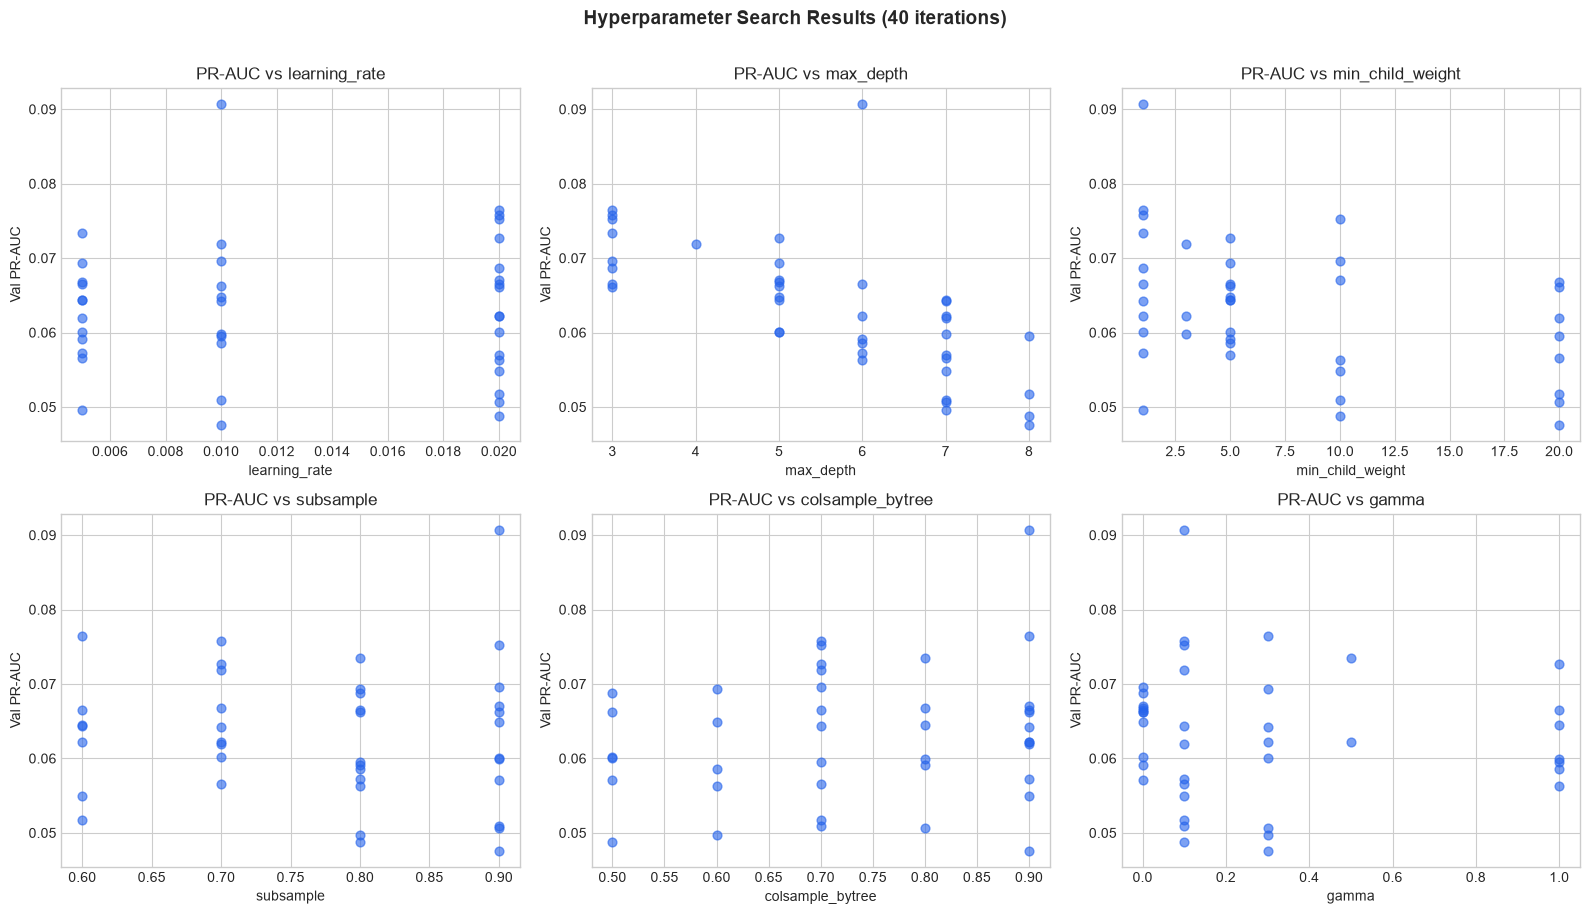


PR-AUC range across search: 0.0476 - 0.0907
Median: 0.0632
Configurations early-stopping before 10 rounds: 1 of 40 (best_iteration median 36, min 1, max 190)


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# PR-AUC vs key hyperparameters
for ax, param in zip(axes.flatten(), ["learning_rate", "max_depth", "min_child_weight",
                                       "subsample", "colsample_bytree", "gamma"]):
    ax.scatter(tuning_df[param], tuning_df["val_pr_auc"], alpha=0.6, s=40, color="#2563eb")
    ax.set_xlabel(param)
    ax.set_ylabel("Val PR-AUC")
    ax.set_title(f"PR-AUC vs {param}")

plt.suptitle("Hyperparameter Search Results (40 iterations)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

print(f"\nPR-AUC range across search: {tuning_df['val_pr_auc'].min():.4f} - {tuning_df['val_pr_auc'].max():.4f}")
print(f"Median: {tuning_df['val_pr_auc'].median():.4f}")

# Size of the degenerate-stopping problem. A configuration that halts in single-digit
# rounds has not boosted; its validation score is a spike in a noisy statistic, not a
# fitted model. The selection cell below excludes these.
degenerate = tuning_df["best_iteration"] < MIN_BOOST_ROUNDS
print(f"Configurations early-stopping before {MIN_BOOST_ROUNDS} rounds: "
      f"{int(degenerate.sum())} of {len(tuning_df)} "
      f"(best_iteration median {int(tuning_df['best_iteration'].median())}, "
      f"min {int(tuning_df['best_iteration'].min())}, "
      f"max {int(tuning_df['best_iteration'].max())})")

### Best Model - Retrain

Retrain the best configuration with a low learning rate and generous tree budget, letting early stopping find the optimal iteration count.

#### A guard on the selection rule

The search above scores each configuration at its own early-stopping optimum, then takes
the best of those. That is a maximum over configurations of a maximum over boosting
rounds, and the statistic being maximised is PR-AUC on 157 validation positives. Two
nested maxima over a noisy statistic will find spikes.

It found one. Left unguarded, the search selects a configuration whose early stopping
fires at round 1 - a two-tree model, validation PR-AUC 0.0907 but validation ROC-AUC
0.7535, against 0.80-0.82 for the configurations ranked immediately behind it that stopped
at 30 to 190 rounds. A model that halts after one round has not boosted. Its PR-AUC is an
accident of where a handful of positives happened to fall in the ranking, not a property
of the data.

The fix is a floor on model form, not a different configuration. `MIN_BOOST_ROUNDS = 10`,
set in the constants cell at the top, makes a configuration eligible only if early stopping
let it reach ten rounds; selection then proceeds by validation PR-AUC as before. The floor
was set without reference to any candidate configuration's test score, and it is applied
to the whole search rather than used to pick a specific row. It is not a tuned quantity
either: the configurations early-stop at 1, 159, 30, 88 and 190 rounds, so any floor
between 2 and 159 returns the same model. Hand-picking the runner-up after seeing its test
score would be selection on the test set - a worse error than the one this guard prevents.

The runner-up may well be what the guard returns. The point is that it is returned by a
rule, not by hindsight.

In [18]:
eligible = tuning_df[tuning_df["best_iteration"] >= MIN_BOOST_ROUNDS]
assert len(eligible) > 0, (
    f"no configuration reached {MIN_BOOST_ROUNDS} boosting rounds - "
    "the search space or early stopping needs revisiting")
n_degenerate = len(tuning_df) - len(eligible)
print(f"{n_degenerate} of {len(tuning_df)} configurations early-stopped before "
      f"{MIN_BOOST_ROUNDS} rounds and were excluded from selection")

best_params = eligible.iloc[0].to_dict()
best_params = {k: int(v) if k in INT_PARAMS else v
               for k, v in best_params.items() if k in param_grid.keys()}

print("Best hyperparameters:")
for k, v in sorted(best_params.items()):
    print(f"  {k}: {v}")

model = xgb.XGBClassifier(
    n_estimators=5000,
    scale_pos_weight=scale_pos,
    eval_metric="aucpr",
    early_stopping_rounds=100,
    random_state=42,
    n_jobs=-1,
    **best_params,
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=100,
)
print(f"\nBest iteration: {model.best_iteration}")

1 of 40 configurations early-stopped before 10 rounds and were excluded from selection
Best hyperparameters:
  colsample_bytree: 0.9
  gamma: 0.3
  learning_rate: 0.02
  max_depth: 3
  min_child_weight: 1
  reg_alpha: 1.0
  reg_lambda: 1.0
  subsample: 0.6
[0]	validation_0-aucpr:0.03902


[100]	validation_0-aucpr:0.07161


[200]	validation_0-aucpr:0.06360


[259]	validation_0-aucpr:0.05953



Best iteration: 159


## Model Evaluation

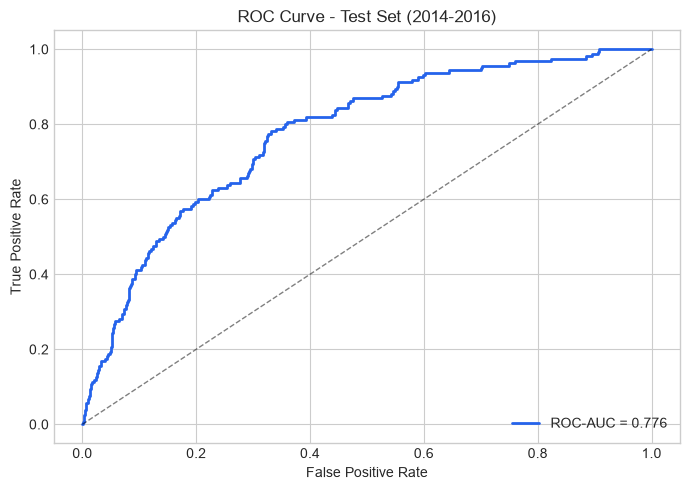

Test ROC-AUC: 0.7760


In [19]:
y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, color="#2563eb", lw=2, label=f"ROC-AUC = {roc_auc:.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve - Test Set (2014-2016)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Test ROC-AUC: {roc_auc:.4f}")


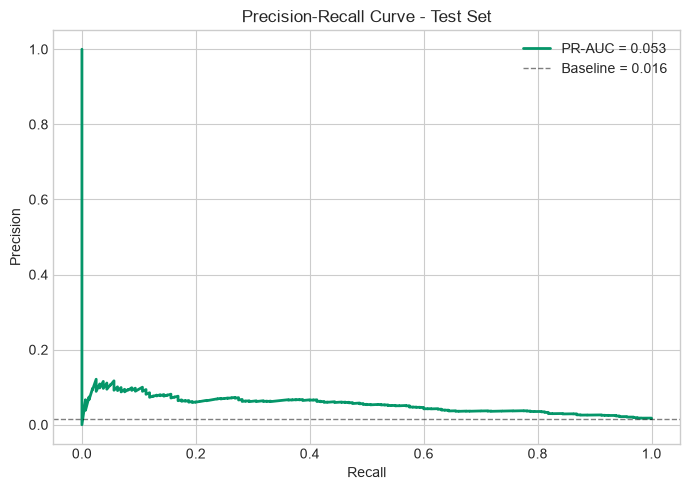

Test PR-AUC:  0.0533   (no-skill baseline = 0.0161)


In [20]:
precision, recall, _ = precision_recall_curve(y_test, y_prob)
# Named test_pr_auc, not pr_auc: the screening section below binds pr_auc to a function
# and a float sitting on that name here would be shadowed either way round.
test_pr_auc = auc(recall, precision)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(recall, precision, color="#059669", lw=2, label=f"PR-AUC = {test_pr_auc:.3f}")
ax.axhline(y=y_test.mean(), color="k", linestyle="--", lw=1, alpha=0.5, label=f"Baseline = {y_test.mean():.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve - Test Set")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Test PR-AUC:  {test_pr_auc:.4f}   (no-skill baseline = {y_test.mean():.4f})")


Flagging the top 5% by score: 498 names (target 498), 30 of 160 defaults caught


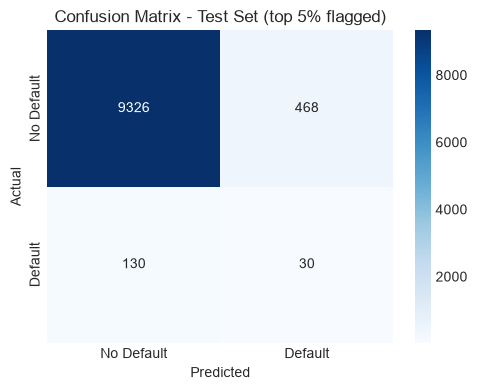

              precision    recall  f1-score   support

  No Default      0.986     0.952     0.969      9794
     Default      0.060     0.188     0.091       160

    accuracy                          0.940      9954
   macro avg      0.523     0.570     0.530      9954
weighted avg      0.971     0.940     0.955      9954



In [21]:
# Operating point is a review budget, not a probability cutoff: flag the riskiest 5%
# of the universe and see what lands in the net.
#
# The threshold is the k-th highest score, matching capture_rate() below exactly. Using
# np.quantile here instead would interpolate between order statistics and flag a
# different set of names, so the confusion matrix and the capture-rate table would
# disagree about the same "top 5%". Ties can still push the flagged count above k; the
# print makes that visible rather than leaving it silent.
BUDGET = 0.05
y_prob = model.predict_proba(X_test)[:, 1]
k = max(1, int(round(BUDGET * len(y_prob))))
budget_threshold = np.sort(y_prob)[::-1][k - 1]
y_pred = (y_prob >= budget_threshold).astype(int)
print(f"Flagging the top {BUDGET:.0%} by score: {int(y_pred.sum())} names "
      f"(target {k}), {int(((y_pred == 1) & (y_test == 1)).sum())} of "
      f"{int(y_test.sum())} defaults caught")

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["No Default", "Default"],
            yticklabels=["No Default", "Default"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix - Test Set (top {BUDGET:.0%} flagged)")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=["No Default", "Default"],
                            digits=3))

### Screening Performance

A probability cutoff is the wrong unit for a credit screen. Analyst time is the binding
constraint, so the question is: given capacity to review the riskiest k% of the universe,
what share of eventual defaults does that net contain?

Capture rate is that share. Lift is precision within the reviewed set divided by the test
base rate - how much more concentrated the flagged names are than a random draw.

Confidence intervals use a cluster bootstrap that resamples **companies**, not rows. The
same firm contributes several correlated firm-years, so a naive row-level bootstrap treats
correlated observations as independent and reports intervals that are far too tight.

In [22]:
def pr_auc(y_true, scores):
    prec, rec, _ = precision_recall_curve(y_true, scores)
    return auc(rec, prec)


def capture_rate(y_true, scores, budgets=(0.01, 0.05, 0.10)):
    """Share of positives captured within the top-k% highest-scoring rows."""
    y_true = np.asarray(y_true)
    ranked = y_true[np.argsort(-np.asarray(scores), kind="mergesort")]
    total_pos = ranked.sum()
    rows = []
    for b in budgets:
        k = max(1, int(round(b * len(ranked))))
        caught = ranked[:k].sum()
        rows.append({
            "budget": f"{b:.0%}",
            "n_reviewed": k,
            "defaults_caught": int(caught),
            "capture_rate": caught / total_pos,
            "precision": caught / k,
            "lift": (caught / k) / y_true.mean(),
        })
    return pd.DataFrame(rows)


def cluster_bootstrap_ci(y_true, scores, groups, metric, n_boot=1000, seed=42):
    """95% CI resampling whole companies, since firm-years within a company correlate."""
    rng = np.random.default_rng(seed)
    y_true, scores, groups = np.asarray(y_true), np.asarray(scores), np.asarray(groups)
    uniq = np.unique(groups)
    index_of = {g: np.flatnonzero(groups == g) for g in uniq}
    stats = []
    for _ in range(n_boot):
        drawn = rng.choice(uniq, size=len(uniq), replace=True)
        idx = np.concatenate([index_of[g] for g in drawn])
        y_b = y_true[idx]
        if y_b.sum() == 0 or y_b.sum() == len(y_b):
            continue          # degenerate resample, no positives or no negatives
        stats.append(metric(y_b, scores[idx]))
    return float(np.percentile(stats, 2.5)), float(np.percentile(stats, 97.5)), len(stats)


def paired_bootstrap_diff_ci(y_true, scores_a, scores_b, groups, metric,
                             n_boot=1000, seed=42):
    """95% CI for metric(a) - metric(b) over the SAME company resamples.

    Two marginal intervals overlapping does not establish that two models are
    indistinguishable - that inference is invalid whenever the estimates are
    correlated, and here they are heavily correlated because both models score the
    identical rows. Bootstrapping the difference on shared draws cancels the common
    sampling noise and answers the comparison directly. Same seed and same draw order
    as cluster_bootstrap_ci, so the resamples are the ones the marginal intervals used.
    """
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    scores_a, scores_b = np.asarray(scores_a), np.asarray(scores_b)
    groups = np.asarray(groups)
    uniq = np.unique(groups)
    index_of = {g: np.flatnonzero(groups == g) for g in uniq}
    diffs = []
    for _ in range(n_boot):
        drawn = rng.choice(uniq, size=len(uniq), replace=True)
        idx = np.concatenate([index_of[g] for g in drawn])
        y_b = y_true[idx]
        if y_b.sum() == 0 or y_b.sum() == len(y_b):
            continue
        diffs.append(metric(y_b, scores_a[idx]) - metric(y_b, scores_b[idx]))
    return float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5)), len(diffs)


all_scores = dict(baseline_scores)
all_scores["XGBoost (tuned)"] = model.predict_proba(X_test)[:, 1]
print(f"scoring {len(all_scores)} models on {len(y_test):,} test rows, "
      f"{int(y_test.sum())} positives, {y_test.mean():.2%} base rate")

scoring 3 models on 9,954 test rows, 160 positives, 1.61% base rate


In [23]:
for name, scores in all_scores.items():
    print(f"\n{name}")
    print(capture_rate(y_test, scores).to_string(index=False))


Altman Z (1968)
budget  n_reviewed  defaults_caught  capture_rate  precision     lift
    1%         100                1       0.00625   0.010000 0.622125
    5%         498                9       0.05625   0.018072 1.124322
   10%         995               21       0.13125   0.021106 1.313028

Logistic regression
budget  n_reviewed  defaults_caught  capture_rate  precision     lift
    1%         100                7       0.04375   0.070000 4.354875
    5%         498               24       0.15000   0.048193 2.998193
   10%         995               47       0.29375   0.047236 2.938681

XGBoost (tuned)
budget  n_reviewed  defaults_caught  capture_rate  precision     lift
    1%         100               10        0.0625   0.100000 6.221250
    5%         498               30        0.1875   0.060241 3.747741
   10%         995               66        0.4125   0.066332 4.126658


In [24]:
groups = test["company_name"]
rows = []
usable = []
for name, scores in all_scores.items():
    roc_lo, roc_hi, n_roc = cluster_bootstrap_ci(y_test, scores, groups, roc_auc_score)
    pr_lo, pr_hi, n_pr = cluster_bootstrap_ci(y_test, scores, groups, pr_auc)
    usable += [n_roc, n_pr]
    cap = capture_rate(y_test, scores, budgets=(0.05,)).iloc[0]
    rows.append({
        "model": name,
        "ROC-AUC": roc_auc_score(y_test, scores),
        "ROC 95% CI": f"[{roc_lo:.3f}, {roc_hi:.3f}]",
        "PR-AUC": pr_auc(y_test, scores),
        "PR 95% CI": f"[{pr_lo:.3f}, {pr_hi:.3f}]",
        "capture@5%": f"{cap['capture_rate']:.1%}",
        "lift@5%": f"{cap['lift']:.2f}x",
    })

comparison = pd.DataFrame(rows)

# cluster_bootstrap_ci drops resamples that come back all-positive or all-negative,
# so an interval can quietly rest on fewer draws than requested. Surface the count
# rather than printing a hardcoded 1,000, and fail if too many were discarded.
assert min(usable) >= 950, \
    f"only {min(usable)} of 1,000 resamples were usable - intervals are unreliable"

print(f"Test set 2014-2016: {len(y_test):,} firm-years, {int(y_test.sum())} defaults, "
      f"{y_test.mean():.2%} base rate")
print(f"Cluster bootstrap: {min(usable):,}-{max(usable):,} usable resamples of 1,000 "
      f"over {groups.nunique():,} companies\n")
print(comparison.to_string(index=False))

Test set 2014-2016: 9,954 firm-years, 160 defaults, 1.61% base rate
Cluster bootstrap: 1,000-1,000 usable resamples of 1,000 over 3,854 companies

              model  ROC-AUC     ROC 95% CI   PR-AUC      PR 95% CI capture@5% lift@5%
    Altman Z (1968) 0.716561 [0.677, 0.753] 0.028225 [0.022, 0.036]       5.6%   1.12x
Logistic regression 0.731623 [0.687, 0.771] 0.044127 [0.028, 0.067]      15.0%   3.00x
    XGBoost (tuned) 0.776001 [0.736, 0.817] 0.053347 [0.038, 0.077]      18.8%   3.75x


In [25]:
# Pairwise differences on shared company resamples. Reading two overlapping marginal
# intervals as "indistinguishable" is not a valid test; this is.
pair_rows = []
usable_diff = []
model_names = list(all_scores)
for i, a in enumerate(model_names):
    for b in model_names[i + 1:]:
        for label, metric in [("ROC-AUC", roc_auc_score), ("PR-AUC", pr_auc)]:
            lo, hi, n = paired_bootstrap_diff_ci(
                y_test, all_scores[a], all_scores[b], groups, metric)
            usable_diff.append(n)
            pair_rows.append({
                "comparison": f"{a} - {b}",
                "metric": label,
                "difference": metric(y_test, all_scores[a]) - metric(y_test, all_scores[b]),
                "95% CI": f"[{lo:+.4f}, {hi:+.4f}]",
                "excludes 0": "yes" if (lo > 0 or hi < 0) else "no",
            })

assert min(usable_diff) >= 950, \
    f"only {min(usable_diff)} of 1,000 paired resamples were usable"

print("Paired cluster bootstrap - both models scored on identical company resamples\n")
print(pd.DataFrame(pair_rows).to_string(index=False))
print("\nAn interval containing 0 means the two models are not separable on that metric "
      "at this sample size.")

Paired cluster bootstrap - both models scored on identical company resamples

                           comparison  metric  difference             95% CI excludes 0
Altman Z (1968) - Logistic regression ROC-AUC   -0.015063 [-0.0605, +0.0318]         no
Altman Z (1968) - Logistic regression  PR-AUC   -0.015902 [-0.0370, -0.0018]        yes
    Altman Z (1968) - XGBoost (tuned) ROC-AUC   -0.059440 [-0.0984, -0.0219]        yes
    Altman Z (1968) - XGBoost (tuned)  PR-AUC   -0.025123 [-0.0477, -0.0118]        yes
Logistic regression - XGBoost (tuned) ROC-AUC   -0.044377 [-0.0792, -0.0113]        yes
Logistic regression - XGBoost (tuned)  PR-AUC   -0.009221 [-0.0320, +0.0145]         no

An interval containing 0 means the two models are not separable on that metric at this sample size.


### Sensitivity Checks

Two questions a reviewer will ask.

**Does performance survive on companies the model has never seen?** The temporal split
does not make company sets disjoint. Restricting the test set to firms absent from
training is the strict check - it removes any benefit the model gets from having seen a
company's accounting fingerprint before.

**Is two years the right horizon?** Rerunning at one and three years shows whether the
result is a property of the data or an artifact of one arbitrary window. Train and test
windows are held fixed across the three runs so that only the label changes; validation
absorbs the differing embargo width. Because those windows differ from the headline split,
the absolute numbers here are not comparable to the table above - only to each other.

In [26]:
seen_companies = set(train["company_name"])
unseen = ~test["company_name"].isin(seen_companies).to_numpy()
y_unseen = np.asarray(y_test)[unseen]

print(f"Test rows from companies absent from training: {unseen.sum():,} of {len(test):,} "
      f"({unseen.mean():.1%}), {int(y_unseen.sum())} defaults, {y_unseen.mean():.2%} base rate")
print(f"Distinct unseen companies: {test.loc[unseen, 'company_name'].nunique():,}\n")

rows = []
for name, scores in all_scores.items():
    s_unseen = np.asarray(scores)[unseen]
    rows.append({
        "model": name,
        "ROC-AUC (all test)": roc_auc_score(y_test, scores),
        "ROC-AUC (unseen only)": roc_auc_score(y_unseen, s_unseen),
        "delta": roc_auc_score(y_unseen, s_unseen) - roc_auc_score(y_test, scores),
    })
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nPR-AUC is omitted here: {int(y_unseen.sum())} positives is too few to estimate it "
      "with useful precision. ROC-AUC is the usable comparison on this subset.")

Test rows from companies absent from training: 3,702 of 9,954 (37.2%), 66 defaults, 1.78% base rate
Distinct unseen companies: 1,590

              model  ROC-AUC (all test)  ROC-AUC (unseen only)     delta
    Altman Z (1968)            0.716561               0.671826 -0.044735
Logistic regression            0.731623               0.671838 -0.059785
    XGBoost (tuned)            0.776001               0.739132 -0.036868

PR-AUC is omitted here: 66 positives is too few to estimate it with useful precision. ROC-AUC is the usable comparison on this subset.


In [27]:
SENS_TRAIN_END = 2005
SENS_TEST = (2014, 2015)

rows = []
test_rows = None
for h in (1, 2, 3):
    val_start, val_end = SENS_TRAIN_END + h + 1, SENS_TEST[0] - h - 1
    assert val_start <= val_end, f"horizon {h} leaves no room for a validation window"

    frame = add_features(build_label(load_raw(), h))
    cols = [c for c in frame.columns if c not in NON_FEATURES]
    tr_h = frame[frame["year"] <= SENS_TRAIN_END]
    va_h = frame[frame["year"].between(val_start, val_end)]
    te_h = frame[frame["year"].between(*SENS_TEST)]

    # Check the embargo against the frames actually built, not against the expressions
    # that defined the boundaries - asserting val_start >= SENS_TRAIN_END + h + 1 right
    # after assigning exactly that is a tautology and can never fire.
    assert tr_h["year"].max() + h < va_h["year"].min(), \
        f"horizon {h}: train labels reach into the validation window"
    assert va_h["year"].max() + h < te_h["year"].min(), \
        f"horizon {h}: validation labels reach into the test window"

    # The whole point of this table is that only the label changes. If the test window
    # drifted between horizons the rows would not be comparable.
    if test_rows is None:
        test_rows = len(te_h)
    assert len(te_h) == test_rows, \
        f"horizon {h}: test window drifted to {len(te_h):,} rows, expected {test_rows:,}"

    prep_h, *_ = fit_prepare(tr_h, cols)

    m_h = xgb.XGBClassifier(
        n_estimators=2000,
        scale_pos_weight=(tr_h["target"] == 0).sum() / tr_h["target"].sum(),
        eval_metric="aucpr", early_stopping_rounds=50, random_state=42, n_jobs=-1,
        **best_params,
    )
    m_h.fit(prep_h(tr_h), tr_h["target"],
            eval_set=[(prep_h(va_h), va_h["target"])], verbose=0)
    s_h = m_h.predict_proba(prep_h(te_h))[:, 1]

    rows.append({
        "horizon_years": h,
        "train": f"1999-{SENS_TRAIN_END}",
        "val": f"{val_start}-{val_end}",
        "test": f"{SENS_TEST[0]}-{SENS_TEST[1]}",
        "test_pos": int(te_h["target"].sum()),
        "base_rate": f"{te_h['target'].mean():.2%}",
        "ROC-AUC": roc_auc_score(te_h["target"], s_h),
        "PR-AUC": pr_auc(te_h["target"], s_h),
    })

print("Horizon sensitivity - hyperparameters held at the h=2 selection, not re-searched\n")
print(pd.DataFrame(rows).to_string(index=False))

Horizon sensitivity - hyperparameters held at the h=2 selection, not re-searched

 horizon_years     train       val      test  test_pos base_rate  ROC-AUC   PR-AUC
             1 1999-2005 2007-2012 2014-2015        61     0.90% 0.814053 0.044661
             2 1999-2005 2008-2011 2014-2015       106     1.56% 0.783667 0.055873
             3 1999-2005 2009-2010 2014-2015       156     2.30% 0.739659 0.068089


## SHAP Feature Importance

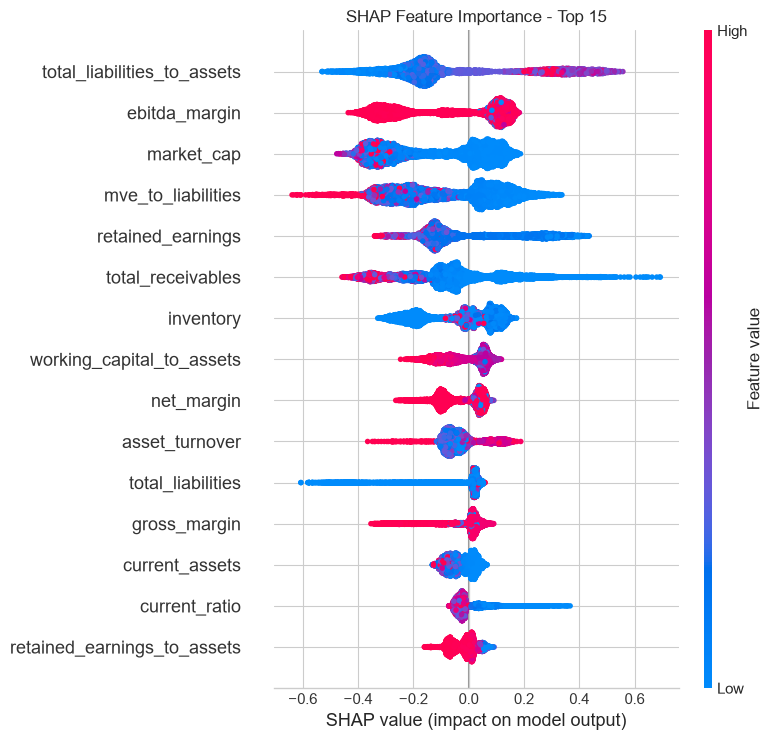

In [28]:
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test, max_display=15, show=False)
plt.title("SHAP Feature Importance - Top 15")
plt.tight_layout()
plt.show()

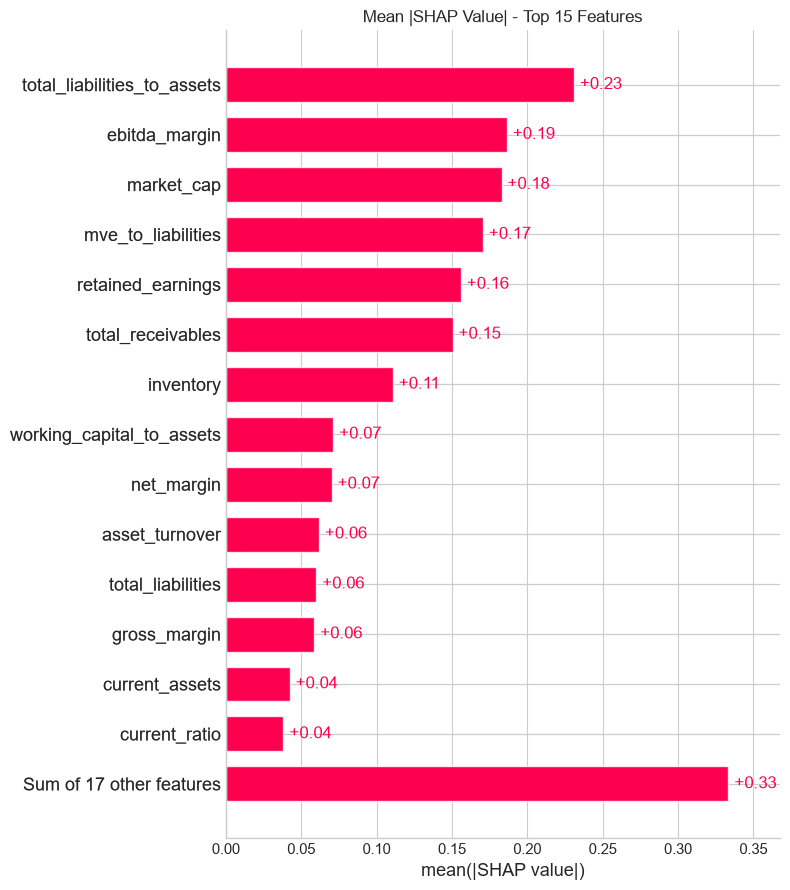

In [29]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Mean |SHAP Value| - Top 15 Features")
plt.tight_layout()
plt.show()

## Results

Test set is 2014-2016 held out entirely: 9,954 firm-years containing 160 labelled failures,
a 1.61% base rate.

| model | ROC-AUC | ROC 95% CI | PR-AUC | PR 95% CI | capture@5% | lift@5% |
|-------|---------|------------|--------|-----------|------------|---------|
| Altman Z (1968) | 0.716561 | [0.677, 0.753] | 0.028225 | [0.022, 0.036] | 5.6% | 1.12x |
| Logistic regression | 0.731623 | [0.687, 0.771] | 0.044127 | [0.028, 0.067] | 15.0% | 3.00x |
| XGBoost (tuned) | 0.776001 | [0.736, 0.817] | 0.053347 | [0.038, 0.077] | 18.8% | 3.75x |

PR-AUC here is the trapezoidal `auc(recall, precision)` rather than
`average_precision_score`; the former runs slightly optimistic in level, and since it
is applied identically to all three models, no comparison between them turns on the
choice.

How to read this: at a 5% review budget (498 names out of 9,954 test firm-years) XGBoost
catches 30 of the 160 eventual failures - 18.8% of them, 3.75x the base rate. Logistic
regression catches 24 (15.0%, 3.00x) and Altman Z catches 9 (5.6%, 1.12x). That is a
universe-narrowing tool for credit work, not a standalone signal.

XGBoost outranks both baselines, and the right instrument says so. Comparing the three
marginal intervals above is not that instrument: two intervals overlapping does not
establish that two models are equivalent, because both are estimated on the same rows and
their errors move together. The paired bootstrap resamples companies once and scores both
models on the identical draw, so the shared noise cancels.

| comparison | metric | difference | 95% CI | excludes 0 |
|---|---|---|---|---|
| Altman Z - Logistic regression | ROC-AUC | -0.0151 | [-0.0605, +0.0318] | no |
| Altman Z - Logistic regression | PR-AUC | -0.0159 | [-0.0370, -0.0018] | yes |
| Altman Z - XGBoost | ROC-AUC | -0.0594 | [-0.0984, -0.0219] | yes |
| Altman Z - XGBoost | PR-AUC | -0.0251 | [-0.0477, -0.0118] | yes |
| Logistic regression - XGBoost | ROC-AUC | -0.0444 | [-0.0792, -0.0113] | yes |
| Logistic regression - XGBoost | PR-AUC | -0.0092 | [-0.0320, +0.0145] | no |

XGBoost beats Altman Z on both metrics and beats logistic regression on ROC-AUC, with the
interval clear of zero in all three cases. It does not separate from logistic regression on
PR-AUC: the gap is 0.0092 and the interval spans zero, which at 160 test positives is what
should be expected. Altman Z and logistic regression are likewise not separable on ROC-AUC.
The defensible summary is that gradient boosting buys a real improvement in global ranking
over both comparators, and an improvement in precision-recall over the 1968 formula only.

The capture-rate table states the same result in the unit a credit analyst works in.

| budget | names reviewed | Altman Z caught (lift) | Logistic caught (lift) | XGBoost caught (lift) |
|---|---|---|---|---|
| 1% | 100 | 1 of 160 (0.62x) | 7 of 160 (4.35x) | 10 of 160 (6.22x) |
| 5% | 498 | 9 of 160 (1.12x) | 24 of 160 (3.00x) | 30 of 160 (3.75x) |
| 10% | 995 | 21 of 160 (1.31x) | 47 of 160 (2.94x) | 66 of 160 (4.13x) |

XGBoost is ahead at all three budgets. Altman Z inverts at 1%, where a lift of 0.62x is
worse than a random draw of the same size - the 1968 formula's most distressed-looking
names default less often than average. The widest absolute gap is at 10%: 66 defaults
against logistic regression's 47 from the same 995 names, 66 of the test period's 160 failures inside a tenth of the universe.

On companies absent from the training set (3,702 rows, 37.2% of test, 66 defaults, 1,590
companies) XGBoost keeps its lead rather than surrendering it: 0.739 against 0.672 for
Altman Z and 0.672 for logistic regression. All three degrade off the full test set, and
XGBoost degrades least (-0.037, against -0.045 for Altman Z and -0.060 for logistic
regression). This is consistent with the ranking advantage not being an artifact of
having seen a firm's accounting fingerprint before, though 66 positives is thin enough
that the ordering is indicative rather than measured. Capture rate and PR-AUC are not
computed on this subset for the same reason.

Horizon sensitivity holds train at 1999-2005 and test at 2014-2015 and varies only the
label window. ROC-AUC falls monotonically as the forecast reaches further out - 0.814 at
one year, 0.784 at two, 0.740 at three - which is the direction a credit analyst would
expect, since accounting data from year `t` says less about year `t+3` than about `t+1`.
PR-AUC moves the other way, 0.0447 to 0.0559 to 0.0681, but that is mechanical rather than
contradictory: the base rate rises from 0.90% to 1.56% to 2.30% across the three labels and
PR-AUC is not comparable across different base rates. Two years is a compromise between
ranking accuracy and a lead time long enough to act on, not the winner on either metric.
